In [30]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

#  BMI

In [31]:
# define state
class BMIState(TypedDict):

    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [32]:
def calculate_bmi(state: BMIState) -> BMIState:

    weight = state['weight_kg']
    height = state['height_m']

    bmi = weight/(height**2)

    state['bmi'] = round(bmi, 2)

    return state

In [33]:
def label_bmi(state: BMIState) -> BMIState:

    bmi = state['bmi']

    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"

    return state


In [34]:
# define your graph
graph = StateGraph(BMIState)

# add nodes to your graph
graph.add_node('calculate_bmi', calculate_bmi)
graph.add_node('label_bmi', label_bmi)

# add edges to your graph
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'label_bmi')
graph.add_edge('label_bmi', END)


# compile the graph
workflow = graph.compile()


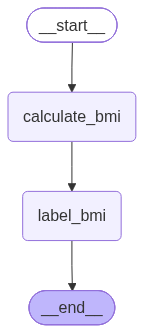

In [35]:
workflow

In [36]:
# execute the graph
intial_state = {'weight_kg':80, 'height_m':1.73}

final_state = workflow.invoke(intial_state)

print(final_state)

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73, 'category': 'Overweight'}


# ChatBot

In [51]:
load_dotenv()

True

In [52]:
model = ChatGroq(model="openai/gpt-oss-120b")

In [53]:
# create a state

class LLMState(TypedDict):

    question: str
    answer: str

In [40]:
def llm_qa(state: LLMState) -> LLMState:

    # extract the question from state
    question = state['question']

    # form a prompt
    prompt = f'Answer the following question {question}'

    # ask that question to the LLM
    answer = model.invoke(prompt).content

    # update the answer in the state
    state['answer'] = answer

    return state

In [41]:
# create our graph

graph = StateGraph(LLMState)

# add nodes
graph.add_node('llm_qa', llm_qa)

# add edges
graph.add_edge(START, 'llm_qa')
graph.add_edge('llm_qa', END)

# compile
workflow = graph.compile()

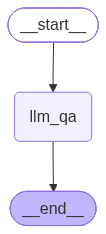

In [42]:
workflow

In [43]:
# execute

intial_state = {'question': 'How far is moon from the earth?'}

final_state = workflow.invoke(intial_state)

print(final_state['answer'])



The Moon orbits Earth at an average distance of about **384,400 kilometers (≈238,900 miles)**.  

Because its orbit is elliptical, the actual distance varies:

- **Perigee (closest approach):** ~363,300 km (≈225,600 mi)  
- **Apogee (farthest point):** ~405,500 km (≈251,900 mi)

These values are averages; the exact distance changes slightly from one orbit to the next due to gravitational influences from the Sun and other bodies.


In [54]:
print(model.invoke('How far is moon from the earth?').content)

The Moon orbits the Earth at an average distance of **about 384,400 kilometers (≈238,900 miles)**.  

Because its orbit is elliptical, the distance varies:

| Position | Approximate distance |
|----------|----------------------|
| **Perigee** (closest point) | ~363,300 km (≈225,700 mi) |
| **Apogee** (farthest point) | ~405,500 km (≈251,900 mi) |
| **Average (mean) distance** | ~384,400 km (≈238,900 mi) |

These figures are based on the geocentric (Earth‑centered) distance to the Moon’s center of mass. The actual distance you’d measure from the surface of the Earth to the surface of the Moon is a few hundred kilometers less, because both bodies have radius (Earth ≈ 6,371 km, Moon ≈ 1,737 km).


# Prompt Chaining

In [45]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [46]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [47]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

In [48]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()


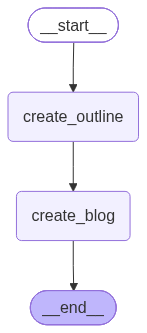

In [49]:
workflow

In [50]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': '**Blog Title:** *The Rise of AI in India: Opportunities, Challenges, and the Road Ahead*\n\n---\n\n## 1. Introduction  \n- **Hook:** A compelling statistic or anecdote (e.g., “India is projected to host 15% of the world’s AI talent by 2030.”)  \n- **Why it matters:** AI’s impact on the economy, society, and global competitiveness.  \n- **Scope of the post:** Overview of the ecosystem, key drivers, success stories, hurdles, and future outlook.\n\n---\n\n## 2. Historical Context  \n### 2.1 Early Foundations  \n- 1960s‑80s: Pioneering research at IITs, ISI, and the Indian Statistical Institute.  \n- 1990s: Government’s IT push and the emergence of software services.  \n\n### 2.2 The Turn of the Century  \n- 2000‑2010: Growth of BPOs and the rise of data‑centric services.  \n- First AI‑related academic programs and research labs.  \n\n### 2.3 The AI Boom (2015‑Present)  \n- Global AI hype meets India’s talent pool.  \n- Key milestones: launch of